In [1]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

In [2]:
train_data = pd.read_csv("sign_mnist_train.csv")
test_data = pd.read_csv("sign_mnist_test.csv")

print(train_data.head())
print(train_data["label"].value_counts())

   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      3     107     118     127     134     139     143     146     150   
1      6     155     157     156     156     156     157     156     158   
2      2     187     188     188     187     187     186     187     188   
3      2     211     211     212     212     211     210     211     210   
4     13     164     167     170     172     176     179     180     184   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0     153  ...       207       207       207       207       206       206   
1     158  ...        69       149       128        87        94       163   
2     187  ...       202       201       200       199       198       199   
3     210  ...       235       234       233       231       230       226   
4     185  ...        92       105       105       108       133       163   

   pixel781  pixel782  pixel783  pixel784  
0       206       204       20

In [3]:
X_train = train_data.drop("label", axis=1).values
y_train = train_data["label"].values

X_test = test_data.drop("label", axis=1).values
y_test = test_data["label"].values

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

Training Shape: (27455, 784)
Testing Shape: (7172, 784)


In [4]:
X_train = X_train.astype("float32")/255.0
X_test = X_test.astype("float32") / 255.0

In [5]:
Anomaly_label = 24
X_normal = X_train[y_train!=Anomaly_label]

X_fit,X_val=train_test_split(
    X_normal,test_size=0.2,random_state=42
)

print("Normal Training Data:", X_fit.shape)
print("Validation Data:", X_val.shape)

Normal Training Data: (21069, 784)
Validation Data: (5268, 784)


In [6]:
model = keras.Sequential([
    keras.Input(shape=(784,)),

    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(64, activation="relu"),

    # Decoder
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(784, activation="sigmoid")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 784)                 │         101,136 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 218,192 (852.31 KB)

 Trainable params: 218,192 (852.31 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [8]:
history= model.fit(
    X_fit,X_fit,
    epochs=10,
    batch_size=32,
    validation_data=(X_val,X_val)
)

Epoch 1/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0181 - mae: 0.0994 - val_loss: 0.0120 - val_mae: 0.0803
Epoch 2/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0101 - mae: 0.0709 - val_loss: 0.0088 - val_mae: 0.0654
Epoch 3/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0083 - mae: 0.0637 - val_loss: 0.0079 - val_mae: 0.0619
Epoch 4/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0076 - mae: 0.0606 - val_loss: 0.0072 - val_mae: 0.0587
Epoch 5/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0071 - mae: 0.0588 - val_loss: 0.0069 - val_mae: 0.0574
Epoch 6/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0068 - mae: 0.0572 - val_loss: 0.0065 - val_mae: 0.0558
Epoch 7/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0065 - mae: 0.0559 - val_loss: 0.0064 - val_mae: 0.0551
Epoch 8/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - loss: 0.0062 - mae: 0.0548 - val_loss: 0.0062 - val_mae: 0.0555
Epoch 9/10
659/659 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - lo

In [9]:
val_predictions = model.predict(X_val)

val_errors = np.mean(
    np.square(X_val-val_predictions), axis=1
)

threshold = np.percentile(val_errors,99)
print("Threshold:", threshold)

165/165 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
Threshold: 0.013700721


In [13]:
predictions = model.predict(X_test)

errors = np.mean(
    np.square(X_test - predictions), axis=1
)

y_pred = (errors > threshold).astype(int)

# Actual labels: 1 = selected anomaly, 0 = normal
y_actual = (y_test == Anomaly_label).astype(int)

print("Predictions:", y_pred[:20])

225/225 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step 
Predictions: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [14]:
print("\nConfusion Matrix:")
print(confusion_matrix(y_actual, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_actual, y_pred, zero_division=0
))


Confusion Matrix:
[[6684  156]
 [ 315   17]]

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97      6840
           1       0.10      0.05      0.07       332

    accuracy                           0.93      7172
   macro avg       0.53      0.51      0.52      7172
weighted avg       0.92      0.93      0.92      7172



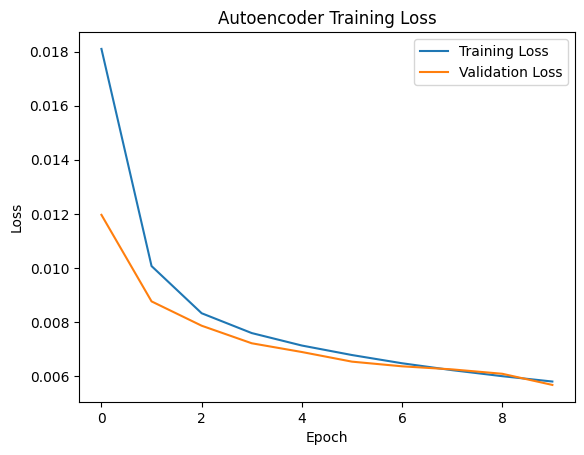

In [15]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

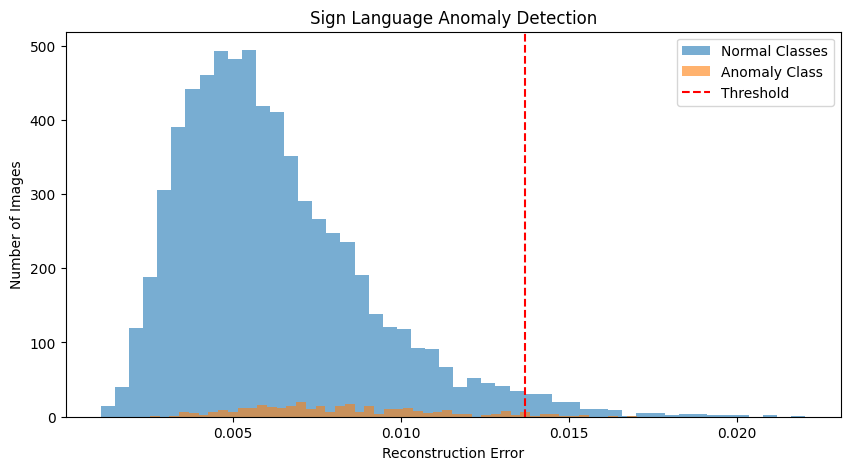

In [16]:
plt.figure(figsize=(10,5))

plt.hist(errors[y_actual == 0], bins=50,
         alpha=0.6, label="Normal Classes")

plt.hist(errors[y_actual == 1], bins=50,
         alpha=0.6, label="Anomaly Class")

plt.axvline(threshold, color="red",
            linestyle="--", label="Threshold")

plt.title("Sign Language Anomaly Detection")
plt.xlabel("Reconstruction Error")
plt.ylabel("Number of Images")
plt.legend()
plt.show()

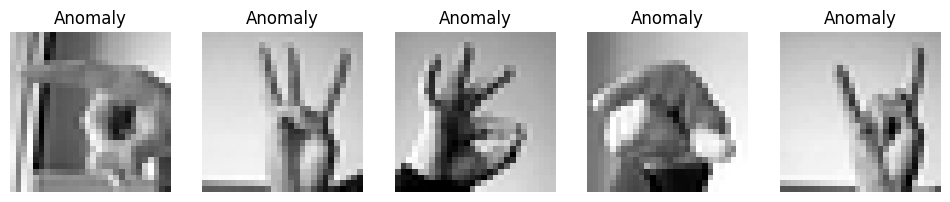

In [17]:
anomaly_indices = np.where(y_pred == 1)[0]

plt.figure(figsize=(12,4))

for i, idx in enumerate(anomaly_indices[:5]):
    plt.subplot(1, 5, i+1)
    plt.imshow(X_test[idx].reshape(28,28), cmap="gray")
    plt.title("Anomaly")
    plt.axis("off")

plt.show()